# Example: Electrometry

Four calculations accompany the electrometry series: measuring inner products, recovering electrode geometry, varying an internal coupling, and reconstructing layer conductivities. The first and third calculations use exact arithmetic; the second and fourth use numerical methods.

[Electrometry](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/en/Resistance%20Geometry%20and%20Duality/Electrometry/Electrometry.md) · [Русский](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/ru/PythonExamples/%D0%9F%D1%80%D0%B8%D0%BC%D0%B5%D1%80%20-%20%D0%AD%D0%BB%D0%B5%D0%BA%D1%82%D1%80%D0%BE%D0%BC%D0%B5%D1%82%D1%80%D0%B8%D1%8F.md)

[Open in Colab](https://colab.research.google.com/github/magin67/pmg-notes/blob/v5/pmg-library/en/PythonExamples/notebooks/electrometry.ipynb) · [Download notebook](https://raw.githubusercontent.com/magin67/pmg-notes/v5/pmg-library/en/PythonExamples/notebooks/electrometry.ipynb)

## Setup

Run the fragments from top to bottom. Checked on Python 3.12 with the pinned `polyform_algebra` commit and the specified versions of the main numerical packages. The notebook includes the same calculations, the input measurement table, editable plotting code, and saved outputs. This note loads the table from a permanent link. Ordinary Python fragments can run locally; the `%pip` installation cell is for Jupyter and Colab.

[polyform-algebra 63d3424](https://github.com/magin67/polyform_algebra/commit/63d342437b0d5973f38befc5183d7f4ea9ecf6f0)

In [1]:
import importlib.metadata as metadata
import json

PACKAGE_URL = "https://github.com/magin67/polyform_algebra/archive/63d342437b0d5973f38befc5183d7f4ea9ecf6f0.zip"
REQUIRED = {"numpy": "2.3.5", "scipy": "1.17.0", "sympy": "1.14.0", "matplotlib": "3.10.8"}
try:
    source = json.loads(metadata.distribution("polyform_algebra").read_text("direct_url.json") or "{}")
    ready = source.get("url") == PACKAGE_URL and all(metadata.version(k) == v for k, v in REQUIRED.items())
except metadata.PackageNotFoundError:
    ready = False
if not ready:
    %pip install -q "https://github.com/magin67/polyform_algebra/archive/63d342437b0d5973f38befc5183d7f4ea9ecf6f0.zip" "numpy==2.3.5" "scipy==1.17.0" "sympy==1.14.0" "matplotlib==3.10.8"
print("Required package revision and numerical dependencies are installed.")

Required package revision and numerical dependencies are installed.


In [2]:
import csv
import io
from fractions import Fraction as Q
from itertools import combinations, product
from string import ascii_lowercase

import numpy as np
import scipy
import sympy as sp
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import least_squares
from polyform_algebra.core import (
    coordinates, dirichlet, gram, green, inner_product,
    kron_reduce, laplacian, network, resistance,
)
from polyform_algebra.variations import vary_conductances

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 130})
print("NumPy", np.__version__, "SciPy", scipy.__version__,
      "SymPy", sp.__version__, "Matplotlib", matplotlib.__version__)

def segment(net, a, b):
    # PMG orientation: (ab) = b - a; both factors change sign for unit currents.
    return coordinates(net.context, {
        v: int(v == b) - int(v == a) for v in net.context.labels
    })

NumPy 2.3.5 SciPy 1.17.0 SymPy 1.14.0 Matplotlib 3.10.8


In [3]:
%matplotlib inline
TEXT = {'original': 'Reference grid', 'two_modes': 'Two-mode reconstruction', 'grid_x': 'Grid spacings along x', 'grid_y': 'Grid spacings along y', 'geometry_title': 'Aligned grids: RMS = 0.232 spacings', 'mode': 'Mode number (descending)', 'eigenvalue': 'Eigenvalue of Gd', 'spectrum_title': 'Spectrum after double centering', 'truth': 'Prescribed medium', 'estimate': 'Reconstruction', 'noisy': '4 unknown layers', 'known': 'Known bottom layer', 'prior': 'Background penalty, λ = 1', 'conductivity': 'Conductivity θ', 'layer': 'Layer number from the surface', 'layers_title': 'The same 120 measurements with 0.1% noise'}

No event loop hook running.


## Notation and functions

| Quantity | Meaning | Code |
| --- | --- | --- |
| $R_{ij}$ | Effective resistance of a finite network | `resistance(net)` |
| $T_{ab,mn}$ | Four-electrode reading $(\varphi_m-\varphi_n)/I$ | `inner_product(net, ab, mn)` |
| $Z_{ij}$ | Pairwise potential coefficients of the real patch | Input CSV; never supplied as network resistances |
| $G_d$ | Double centering of $D_{ij}=1/Z_{ij}^2$ | `-0.5 * J @ D @ J` |
| $K=L_{\partial}$ | Laplacian of the equivalent electrode network | `laplacian(kron_reduce(...).value.network)` |
| $S$ | Resistance sensitivity to conductances, with the minus sign factored out | Entrywise squares of `gram(...)` |

Here $G_d$ describes the geometry of transformed pairwise data. It is not a network Greenian. The third and fourth calculations have access to complete model values of $R$; the first explains why these cannot automatically be treated as known from experiments on four distinct electrodes.

## What four electrodes determine

For a prescribed network, compare the inner product with

$$
T_{ab,mn}=\frac12(R_{an}+R_{bm}-R_{am}-R_{bn}).
$$

Four distinct electrodes have three partitions into a current pair and a sensing pair. Matrix `M` maps the six pairwise values of $R$ to these three readings. Check its rank and its insensitivity to additions $\varepsilon_i+\varepsilon_j$ for $i\ne j$; the diagonal remains zero.


[Related note](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/en/Resistance%20Geometry%20and%20Duality/Electrometry/What%20Electrometry%20Measures.md).

In [4]:
electrodes = tuple("abcd")
four = network(electrodes, [
    ("a", "b", 2), ("b", "c", 1), ("c", "d", 3),
    ("d", "a", 1), ("a", "c", Q(1, 2)),
])
R = sp.Matrix(resistance(four).value.values)
pairs4 = tuple(combinations(range(4), 2))
pairings = ((0, 1, 2, 3), (0, 2, 1, 3), (0, 3, 1, 2))
measurement_rows, measured = [], []
for a, b, m, n in pairings:
    scalar = inner_product(four, segment(four, electrodes[a], electrodes[b]),
                           segment(four, electrodes[m], electrodes[n])).value
    formula = (R[a, n] + R[b, m] - R[a, m] - R[b, n]) / 2
    assert scalar == formula
    row = [Q(0) for _ in pairs4]
    for i, j, sign in ((a, n, 1), (b, m, 1), (a, m, -1), (b, n, -1)):
        row[pairs4.index(tuple(sorted((i, j))))] += Q(sign, 2)
    measurement_rows.append(row)
    measured.append(scalar)
M = sp.Matrix(measurement_rows)
assert M.rank() == 2 and measured[0] - measured[1] + measured[2] == 0
# Each column adds epsilon_i + epsilon_j to an off-diagonal pair entry.
vertex_additions = sp.Matrix([[int(k == i) + int(k == j) for k in range(4)]
                             for i, j in pairs4])
assert M * vertex_additions == sp.zeros(3, 4)
assert vertex_additions.rank() == 4
print("T_ab,cd; T_ac,bd; T_ad,bc =", measured)
print("rank(M) =", M.rank(), "; dim ker(M) =", len(pairs4) - M.rank())

T_ab,cd; T_ac,bd; T_ad,bc = [Fraction(-1, 23), Fraction(5, 23), Fraction(6, 23)]
rank(M) = 2 ; dim ker(M) = 4


The values are $T_{ab,cd}=-1/23$, $T_{ac,bd}=5/23$, and $T_{ad,bc}=6/23$, with $T_{ab,cd}-T_{ac,bd}+T_{ad,bc}=0$. The rank is 2 and the kernel dimension is 4. This checks arbitrary pair coordinates, rather than the independence of parameters of a particular ground model. Contact additions are treated separately in the [KVP example](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/en/PythonExamples/Example%20-%20KVP%20Decomposition.md#contacts-and-a-conductance-change).

## Geometry from real pairwise data

Use the table published with the series: 16 electrodes and 120 pairs. Coordinates are in grid spacings; `Z` retains the scale of the source data. Geometric comparison allows one common scale, translation, and an orthogonal transformation. The reference coordinates are not used to extract the two modes; they are used for alignment and error assessment.

The notebook embeds a copy of the CSV. Its checksum is computed after normalizing line endings to `LF`.

[Related note](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/en/Resistance%20Geometry%20and%20Duality/Electrometry/Properties%20of%20Resistances%20in%20a%20Continuous%20Medium.md).

[CSV](https://github.com/magin67/pmg-notes/blob/f27cf204e671da5381df2c370aed70cc14d5e4ac/pmg-library/en/Resistance%20Geometry%20and%20Duality/Electrometry/data/Measurements%20on%20a%204%20by%204%20patch.csv).

In [5]:
DATA_CSV = """id1,id2,x1,y1,x2,y2,Z
1,2,0,0,1,0,7.47
1,3,0,0,2,0,2.8
1,4,0,0,3,0,1.45
1,14,0,0,0,1,9.01
1,15,0,0,1,1,4.74
1,16,0,0,2,1,2.32
1,17,0,0,3,1,1.29
1,27,0,0,0,2,2.93
1,28,0,0,1,2,2.43
1,29,0,0,2,2,1.65
1,30,0,0,3,2,1.06
1,40,0,0,0,3,1.51
1,41,0,0,1,3,1.38
1,42,0,0,2,3,1.03
1,43,0,0,3,3,0.75
2,3,1,0,2,0,8.2
2,4,1,0,3,0,2.95
2,14,1,0,0,1,4.67
2,15,1,0,1,1,7.15
2,16,1,0,2,1,4.53
2,17,1,0,3,1,2.29
2,27,1,0,0,2,2.26
2,28,1,0,1,2,2.75
2,29,1,0,2,2,2.36
2,30,1,0,3,2,1.61
2,40,1,0,0,3,1.3
2,41,1,0,1,3,1.44
2,42,1,0,2,3,1.26
2,43,1,0,3,3,0.99
3,4,2,0,3,0,8.21
3,14,2,0,0,1,2.39
3,15,2,0,1,1,4.84
3,16,2,0,2,1,7.94
3,17,2,0,3,1,4.61
3,27,2,0,0,2,1.6
3,28,2,0,1,2,2.44
3,29,2,0,2,2,2.96
3,30,2,0,3,2,2.43
3,40,2,0,0,3,1.07
3,41,2,0,1,3,1.37
3,42,2,0,2,3,1.43
3,43,2,0,3,3,1.28
4,14,3,0,0,1,1.35
4,15,3,0,1,1,2.44
4,16,3,0,2,1,4.9
4,17,3,0,3,1,6.96
4,27,3,0,0,2,1.05
4,28,3,0,1,2,1.64
4,29,3,0,2,2,2.43
4,30,3,0,3,2,2.78
4,40,3,0,0,3,0.79
4,41,3,0,1,3,1.06
4,42,3,0,2,3,1.28
4,43,3,0,3,3,1.39
14,15,0,1,1,1,7.52
14,16,0,1,2,1,2.79
14,17,0,1,3,1,1.44
14,27,0,1,0,2,7.2
14,28,0,1,1,2,4.55
14,29,0,1,2,2,2.36
14,30,0,1,3,2,1.33
14,40,0,1,0,3,2.74
14,41,0,1,1,3,2.32
14,42,0,1,2,3,1.52
14,43,0,1,3,3,0.98
15,16,1,1,2,1,7.84
15,17,1,1,3,1,2.87
15,27,1,1,0,2,4.57
15,28,1,1,1,2,7.86
15,29,1,1,2,2,5.01
15,30,1,1,3,2,2.47
15,40,1,1,0,3,2.37
15,41,1,1,1,3,2.91
15,42,1,1,2,3,2.31
15,43,1,1,3,3,1.53
16,17,2,1,3,1,7.69
16,27,2,1,0,2,2.32
16,28,2,1,1,2,4.86
16,29,2,1,2,2,7.99
16,30,2,1,3,2,5.0
16,40,2,1,0,3,1.61
16,41,2,1,1,3,2.44
16,42,2,1,2,3,2.77
16,43,2,1,3,3,2.29
17,27,3,1,0,2,1.31
17,28,3,1,1,2,2.44
17,29,3,1,2,2,5.07
17,30,3,1,3,2,8.53
17,40,3,1,0,3,1.06
17,41,3,1,1,3,1.67
17,42,3,1,2,3,2.41
17,43,3,1,3,3,2.94
27,28,0,2,1,2,7.14
27,29,0,2,2,2,2.74
27,30,0,2,3,2,1.43
27,40,0,2,0,3,7.16
27,41,0,2,1,3,4.49
27,42,0,2,2,3,2.19
27,43,0,2,3,3,1.2
28,29,1,2,2,2,7.76
28,30,1,2,3,2,2.89
28,40,1,2,0,3,4.7
28,41,1,2,1,3,7.89
28,42,1,2,2,3,4.5
28,43,1,2,3,3,2.18
29,30,2,2,3,2,8.05
29,40,2,2,0,3,2.36
29,41,2,2,1,3,4.9
29,42,2,2,2,3,7.19
29,43,2,2,3,3,4.35
30,40,3,2,0,3,1.33
30,41,3,2,1,3,2.45
30,42,3,2,2,3,4.78
30,43,3,2,3,3,7.59
40,41,0,3,1,3,7.39
40,42,0,3,2,3,2.73
40,43,0,3,3,3,1.35
41,42,1,3,2,3,7.62
41,43,1,3,3,3,2.66
42,43,2,3,3,3,7.1
"""
import hashlib
DATA_CSV = DATA_CSV.replace("\r\n", "\n").replace("\r", "\n")
assert hashlib.sha256(DATA_CSV.encode()).hexdigest() == "d3fc72adc6b098166c569a41cdebe53176d3d6e1973849dc841e7cc8b7151f5f"

The homogeneous model uses $Z_{ij}=1/d_{ij}$ for $i\ne j$. The entrywise transformation and centering are

$$
D_{ij}=Z_{ij}^{-2}\quad(i\ne j),\qquad D_{ii}=0,
\qquad J=I-\frac1{16}\mathbf1\mathbf1^{\mathsf T},
\qquad G_d=-\frac12 JDJ.
$$

On the ideal planar grid, $D$ has rank 4 while $G_d$ has rank 2. It is the centered matrix that has two geometric modes. The same procedure is then applied to the measured table. Coordinates use the eigenvectors and the two largest positive eigenvalues.

In [6]:
records = list(csv.DictReader(io.StringIO(DATA_CSV)))
ids = sorted({int(row[k]) for row in records for k in ("id1", "id2")})
assert len(ids) == 16 and len(records) == 120
lookup = {value: i for i, value in enumerate(ids)}
Z = np.zeros((16, 16))
xy, seen = {}, set()
for row in records:
    a, b = int(row["id1"]), int(row["id2"])
    assert a < b and (a, b) not in seen
    seen.add((a, b))
    for ident, suffix in ((a, "1"), (b, "2")):
        point = (float(row["x" + suffix]), float(row["y" + suffix]))
        assert ident not in xy or xy[ident] == point
        xy[ident] = point
    value = float(row["Z"])
    assert np.isfinite(value) and value > 0
    Z[lookup[a], lookup[b]] = Z[lookup[b], lookup[a]] = value
X = np.array([xy[ident] for ident in ids])
X0 = X - X.mean(axis=0)
mask = ~np.eye(16, dtype=bool)
J = np.eye(16) - np.ones((16, 16)) / 16

def distance_gram(pair_values):
    D = np.zeros_like(pair_values)
    D[mask] = pair_values[mask] ** -2  # Entrywise, not a matrix inverse.
    return D, -0.5 * J @ D @ J

distances = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=2)
Z_ideal = np.zeros_like(Z)
Z_ideal[mask] = 1 / distances[mask]  # kappa = 1, grid spacing = 1.
D0, G0 = distance_gram(Z_ideal)
assert np.allclose(G0, X0 @ X0.T)
assert np.linalg.matrix_rank(D0) == 4
assert np.linalg.matrix_rank(G0) == 2
D, Gd = distance_gram(Z)
eigenvalues, eigenvectors = np.linalg.eigh(Gd)
assert np.all(eigenvalues[-2:] > 0)
Y = eigenvectors[:, -2:] * np.sqrt(eigenvalues[-2:])
# Similarity alignment: one scale, rotation/reflection, translation; no shear.
left, singular_alignment, right = np.linalg.svd(Y.T @ X0)
scale = singular_alignment.sum() / np.sum(Y * Y)
recovered = scale * Y @ (left @ right) + X.mean(axis=0)
rmse = np.sqrt(np.mean(np.sum((recovered - X) ** 2, axis=1)))
D_back = np.diag(Gd)[:, None] + np.diag(Gd)[None, :] - 2 * Gd
assert np.allclose(D_back, D)
assert np.isclose(rmse, 0.23163170447, atol=1e-9)
print("rank(D_ideal), rank(G_ideal) =", np.linalg.matrix_rank(D0), np.linalg.matrix_rank(G0))
print("RMSE / grid spacing =", round(float(rmse), 6))
print("eigenvalues(G_d), descending =", eigenvalues[::-1])

rank(D_ideal), rank(G_ideal) = 4 2
RMSE / grid spacing = 0.231632
eigenvalues(G_d), descending = [ 1.550756  1.414629  0.002609  0.001591  0.       -0.000179 -0.000956
 -0.001391 -0.002483 -0.003215 -0.004558 -0.031136 -0.034808 -0.138813
 -0.287493 -0.434423]


The root mean square alignment error is **0.231632 grid spacings**. The two leading modes reproduce the overall patch geometry. The remaining modes retain their signs, including negative eigenvalues. They cannot automatically be attributed to heterogeneity: $1/Z^2$ amplifies errors in small $Z$, and the measurement error model is unknown.

The complete matrix $G_d$ returns the original $D$ through $D_{ij}=(G_d)_{ii}+(G_d)_{jj}-2(G_d)_{ij}$. The code checks this reconstruction. Keeping two modes is an approximation; eigenvalues alone do not determine the pairwise table.

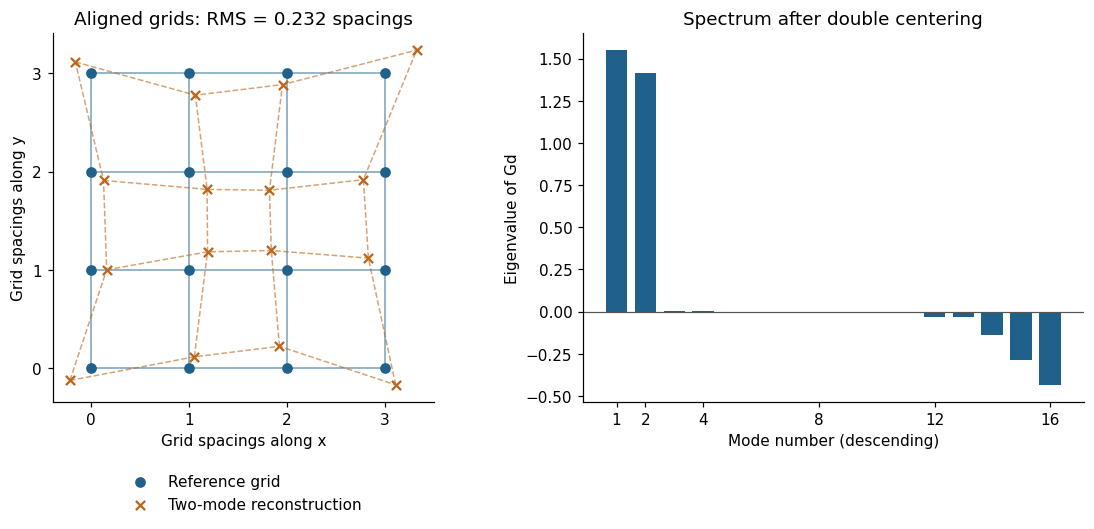

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.7), layout="constrained")
ax = axes[0]
for grid, color, style in ((X, "#20618C", "-"), (recovered, "#BB661C", "--")):
    for dim in (0, 1):
        for value in np.unique(X[:, dim]):
            take = np.flatnonzero(X[:, dim] == value)
            take = take[np.argsort(X[take, 1 - dim])]
            ax.plot(grid[take, 0], grid[take, 1], style, color=color, alpha=0.6, lw=1)
ax.scatter(*X.T, color="#20618C", marker="o", label=TEXT["original"], zorder=3)
ax.scatter(*recovered.T, color="#BB661C", marker="x", label=TEXT["two_modes"], zorder=4)
ax.set(xlabel=TEXT["grid_x"], ylabel=TEXT["grid_y"], aspect="equal",
       title=TEXT["geometry_title"], xticks=range(4), yticks=range(4))
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16))
rank = np.arange(1, 17)
values = eigenvalues[::-1]
axes[1].bar(rank, values, color="#20618C", width=0.75)
axes[1].axhline(0, color="#555555", lw=0.8)
axes[1].set(xlabel=TEXT["mode"], ylabel=TEXT["eigenvalue"],
            title=TEXT["spectrum_title"], xticks=[1, 2, 4, 8, 12, 16])
fig.savefig("electrometry-geometry.svg", bbox_inches="tight")
plt.show()

## Varying an internal coupling

Four electrodes $a,b,c,d$ connect to internal vertices $p,q$: couplings $ap,bp,cq,dq$ are unit, while $pq$ has conductance $t$. Evaluate at $t=1$. All model-network quantities are dimensionless.

Let $P$ extend electrode potentials to all vertices and let $b=e_q-e_p$. Compare two expressions for the same derivative:

$$
\frac{dK}{dt}=P^{\mathsf T}bb^{\mathsf T}P
=\frac12 K\frac{dR_{\partial}}{dt}K.
$$

Each resistance derivative is computed through the squared inner product with $(pq)$. The calculation also checks that Kron reduction preserves electrode resistances.


[Related note](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/en/Resistance%20Geometry%20and%20Duality/Electrometry/Resistance%20Variations%20in%20Graphs%20and%20Continuous%20Media.md).

In [8]:
labels = tuple("abcdpq")
bridge = network(labels, [("a", "p", 1), ("b", "p", 1),
                          ("c", "q", 1), ("d", "q", 1), ("p", "q", 1)])
Rb = sp.Matrix(resistance(bridge).value.values)
b = sp.Matrix(segment(bridge, "p", "q").values)
transfer = sp.Matrix(gram(bridge,
    tuple(segment(bridge, labels[i], labels[j]) for i, j in pairs4),
    (segment(bridge, "p", "q"),)).value.values)
dr = -transfer.applyfunc(lambda value: value ** 2)
dR = sp.zeros(4)
for k, (i, j) in enumerate(pairs4):
    dR[i, j] = dR[j, i] = dr[k]
reduced = kron_reduce(bridge, electrodes).value.network
K = sp.Matrix(laplacian(reduced).value.values)
assert sp.Matrix(resistance(reduced).value.values) == Rb[:4, :4]
P = sp.Matrix(dirichlet(bridge, electrodes).value.H.values)
dK_fields = P.T * (b * b.T) * P
dK_resistances = K * dR * K / 2
v = sp.Matrix([1, 1, -1, -1])
assert dK_fields == dK_resistances == v * v.T / 16
print("pair   R(t=1)   dR/dt   c_boundary   dc_boundary/dt")
for k, (i, j) in enumerate(pairs4):
    print(labels[i] + labels[j], Rb[i, j], dr[k], -K[i, j], -dK_fields[i, j])

pair   R(t=1)   dR/dt   c_boundary   dc_boundary/dt
ab 2 0 3/8 -1/16
ac 3 -1 1/8 1/16
ad 3 -1 1/8 1/16
bc 3 -1 1/8 1/16
bd 3 -1 1/8 1/16
cd 2 0 3/8 -1/16


Pairs $ab,cd$ give $R=2$ and $dR/dt=0$; the four cross pairs give $R=3$ and $dR/dt=-1$. The effective conductances of $ab,cd$ decrease with derivative $-1/16$, while the cross conductances increase with derivative $1/16$. One internal change affects several couplings of the equivalent network.

The next check uses quadric connectivity. On the complete set of six electrode pairs, form the square matrices $S_{\partial}$ and $L^{(q)}$:

$$
(L^{(q)})_{ij,kl}=\frac12(K_{ik}K_{jl}+K_{il}K_{jk}),
\qquad S_{\partial}L^{(q)}=I,
\qquad dc_{\partial}=-L^{(q)}dR_{\partial}.
$$

The last expression recovers changes of **effective electrode couplings**. It does not determine the internal medium. Derivatives are also compared with a finite increment of $10^{-5}$ in $t$.

In [9]:
# Six electrode pairs versus six effective couplings: a square inverse relation.
Gr_boundary = sp.Matrix(green(reduced).value.values)
B = sp.Matrix.hstack(*(sp.eye(4)[:, i] - sp.eye(4)[:, j] for i, j in pairs4))
S_boundary = (B.T * Gr_boundary * B).applyfunc(lambda value: value ** 2)
Lq = sp.Matrix([[(K[i, k] * K[j, l] + K[i, l] * K[j, k]) / 2
                for k, l in pairs4] for i, j in pairs4])
assert S_boundary * Lq == sp.eye(6)
dc = -Lq * dr
assert dc == sp.Matrix([-dK_fields[i, j] for i, j in pairs4])
# Check the derivative against an actual finite conductance change.
step = Q(1, 100000)
changed = vary_conductances(bridge, {("p", "q"): step})
R_changed = sp.Matrix(resistance(changed).value.values)[:4, :4]
K_changed = sp.Matrix(laplacian(kron_reduce(changed, electrodes).value.network).value.values)
error_R = max(abs(value) for value in (R_changed - Rb[:4, :4]) / step - dR)
error_K = max(abs(value) for value in (K_changed - K) / step - dK_fields)
assert error_R < step and error_K < step
print("S_boundary * Lq = I_6:", S_boundary * Lq == sp.eye(6))
print("finite-step derivative errors:", float(error_R), float(error_K))

S_boundary * Lq = I_6: True
finite-step derivative errors: 9.99990000099999e-06 3.1249843750781247e-07


## Reconstructing four layers

A finite $4\times4\times4$ grid has 64 vertices and 144 nearest-neighbor couplings. Its top face carries 16 electrodes. All 120 model resistances are used. No couplings extend beyond the box; this is a finite network, not a validated approximation of an infinite half-space.

Four positive parameters $\theta_1,\ldots,\theta_4$ describe layer conductivities. A horizontal conductance equals its layer parameter; a vertical conductance between adjacent layers equals their harmonic mean. Matrix $H=\partial c/\partial\theta$ maps four parameter changes to 144 coupling changes. The measurement Jacobian is

$$
A=\frac{\partial R}{\partial\theta}=-SH.
$$

`polyform_algebra` constructs the network and computes resistances and inner products. Repeated fitting steps use a direct SciPy solve of the same system. Its values and the entire matrix $S$ are checked against the package on homogeneous and prescribed heterogeneous networks; each fitted model is checked through the package again. Numbers in arrays are indices; package vertices have letter labels.


[Related note](https://github.com/magin67/pmg-notes/blob/v5/pmg-library/en/Resistance%20Geometry%20and%20Duality/Electrometry/Reconstructing%20Couplings%20with%20a%20Prescribed%20Neighbor%20Structure.md).

In [10]:
N = 4
XYZ = np.array(list(product(range(N), repeat=3)))
INDEX = {tuple(point): k for k, point in enumerate(XYZ)}
EDGES = []
for i, point in enumerate(XYZ):
    for axis in range(3):
        other = point.copy()
        other[axis] += 1
        if other[axis] < N:
            EDGES.append((i, INDEX[tuple(other)]))
EDGES = np.array(EDGES)
TOP = tuple(map(int, np.flatnonzero(XYZ[:, 2] == 0)))
PAIRS = tuple(combinations(TOP, 2))
GRID_LABELS = tuple((list(ascii_lowercase) +
                    [a + b for a in ascii_lowercase for b in ascii_lowercase])[:len(XYZ)])
LABELED_PAIRS = tuple((GRID_LABELS[i], GRID_LABELS[j]) for i, j in PAIRS)
INC = np.zeros((len(XYZ), len(EDGES)))
for k, (i, j) in enumerate(EDGES):
    INC[i, k], INC[j, k] = 1.0, -1.0
CURRENT = np.zeros((len(XYZ), len(PAIRS)))
for k, (i, j) in enumerate(PAIRS):
    CURRENT[i, k], CURRENT[j, k] = 1.0, -1.0
assert (len(XYZ), len(EDGES), len(TOP), len(PAIRS)) == (64, 144, 16, 120)

def grid_network(c):
    return network(GRID_LABELS,
                   [(GRID_LABELS[i], GRID_LABELS[j], float(value)) for (i, j), value in zip(EDGES, c)],
                   arithmetic="numeric")

def edge_response(c):
    # Fix the last potential to zero; retain all 144 neighboring couplings.
    A, Bcurr = INC[:-1], CURRENT[:-1]
    L_ground = (A * c) @ A.T
    U = cho_solve(cho_factor(L_ground, lower=True), Bcurr)
    R_pairs = np.sum(Bcurr * U, axis=0)
    S = (A.T @ U).T ** 2
    return R_pairs, S

In [11]:
def layer_map(theta):
    c = np.empty(len(EDGES))
    H = np.zeros((len(EDGES), N))
    for k, (i, j) in enumerate(EDGES):
        z, w = XYZ[i, 2], XYZ[j, 2]
        if z == w:
            c[k], H[k, z] = theta[z], 1.0
        else:
            total = theta[z] + theta[w]
            c[k] = 2 * theta[z] * theta[w] / total
            H[k, z] = 2 * theta[w] ** 2 / total ** 2
            H[k, w] = 2 * theta[z] ** 2 / total ** 2
    return c, H

def forward(theta):
    c, H = layer_map(theta)
    R_pairs, S = edge_response(c)
    return R_pairs, -S @ H

The prescribed medium has parameters $(1,1.15,0.85,1.1)$. Its Jacobian is independently checked by central finite differences.

Matrix $S$ is $120\times144$, and $A$ is $120\times4$. Singular values of the normalized Jacobian $\operatorname{diag}(1/R_0)A$ assess how well layer changes can be distinguished. They are not the spectrum of the geometric matrix $G_d$ in the earlier calculation. Here $R_0$ denotes the resistances of the homogeneous network with $\theta=(1,1,1,1)$.

In [12]:
truth = np.array([1.0, 1.15, 0.85, 1.1])
r0, jac0 = forward(np.ones(N))
rtrue, jac_true = forward(truth)
truth_c, _ = layer_map(truth)
# Validate the fast repeated solves against the package, including the Jacobian.
for c in (np.ones(len(EDGES)), truth_c):
    net = grid_network(c)
    r_fast, s_fast = edge_response(c)
    r_package = np.array(resistance(net, pairs=LABELED_PAIRS).value.values, dtype=float)
    assert np.allclose(r_fast, r_package, rtol=1e-10, atol=1e-12)
    pair_vectors = tuple(segment(net, a, b) for a, b in LABELED_PAIRS)
    edge_vectors = tuple(segment(net, GRID_LABELS[i], GRID_LABELS[j]) for i, j in EDGES)
    s_package = gram(net, pair_vectors, edge_vectors).value.to_numpy() ** 2
    assert np.allclose(s_fast, s_package, rtol=1e-9, atol=1e-12)
h = 1e-5
jac_difference = np.column_stack([
    (forward(truth + h * np.eye(N)[k])[0] - forward(truth - h * np.eye(N)[k])[0]) / (2*h)
    for k in range(N)
])
assert np.max(np.abs(jac_difference - jac_true)) < 1e-8
singular = np.linalg.svd(jac0 / r0[:, None], compute_uv=False)
known_reference = np.r_[np.ones(N - 1), truth[-1]]
jac_three = forward(known_reference)[1][:, :3] / r0[:, None]
singular_three = np.linalg.svd(jac_three, compute_uv=False)
print("S shape:", s_fast.shape, "; A = -S H shape:", jac0.shape)
print("singular values of A / R0:", singular)
print("condition, four parameters:", round(float(singular[0] / singular[-1]), 2))
print("condition, known bottom:", round(float(singular_three[0] / singular_three[-1]), 2))

S shape: (120, 144) ; A = -S H shape: (120, 4)
singular values of A / R0: [8.936209 0.450426 0.022028 0.000983]
condition, four parameters: 9087.93
condition, known bottom: 445.56


The ratio of the largest to smallest singular value is about 9088 for the four-parameter model. With the bottom layer fixed it is about 446; the three-parameter derivative is evaluated at $(1,1,1,1.1)$. These condition numbers refer to the stated reference points and the same row normalization.

Compare exact data with data perturbed by independent Gaussian noise of standard deviation $0.001R_{0,ij}$. The three noisy cases share the same realization, `seed=1304`. All cases impose $0.5\le\theta_i\le1.5$. The objective is the sum of squared normalized residuals; the final case adds $\lambda\sum_i(\theta_i-1)^2$ with $\lambda=1$. This penalty strength is illustrative, with no claim of optimal selection.

In [13]:
eta = 0.001
noise = eta * r0 * np.random.default_rng(1304).normal(size=len(PAIRS))
observed = rtrue + noise

def fit(observed, scale, fixed_bottom=None, regularization=0.0):
    count = N if fixed_bottom is None else N - 1
    def full_theta(x):
        return x if fixed_bottom is None else np.r_[x, fixed_bottom]
    def residual(x):
        data = (forward(full_theta(x))[0] - observed) / scale
        return np.r_[data, np.sqrt(regularization) * (x - 1)]
    def jacobian(x):
        data = forward(full_theta(x))[1][:, :count] / scale[:, None]
        return np.vstack([data, np.sqrt(regularization) * np.eye(count)])
    result = least_squares(residual, np.ones(count), jac=jacobian, bounds=(0.5, 1.5),
                           method="trf", ftol=1e-12, xtol=1e-12, gtol=1e-12,
                           max_nfev=500)
    assert result.success, result.message
    theta = full_theta(result.x)
    rms = 100 * np.sqrt(np.mean(((forward(theta)[0] - observed) / r0) ** 2))
    return theta, rms

scenarios = [
    ("exact", rtrue, r0, None, 0.0),
    ("noisy", observed, eta * r0, None, 0.0),
    ("known", observed, eta * r0, truth[-1], 0.0),
    ("prior", observed, eta * r0, None, 1.0),
]
fits = {}
print("case     theta_1  theta_2  theta_3  theta_4    RMS, %")
for key, data, scale_fit, bottom, alpha in scenarios:
    theta, rms = fit(data, scale_fit, bottom, alpha)
    fits[key] = (theta, rms)
    print(f"{key:6s}", " ".join(f"{value:8.4f}" for value in theta), f" {rms:.6f}")
    checked = np.array(resistance(grid_network(layer_map(theta)[0]), pairs=LABELED_PAIRS).value.values, dtype=float)
    assert np.allclose(checked, forward(theta)[0], rtol=1e-10, atol=1e-12)
assert np.max(np.abs(fits["exact"][0] - truth)) < 1e-7
assert fits["known"][0][-1] == truth[-1]
assert fits["noisy"][0][-1] > 1.49
assert all(0.09 < fits[key][1] < 0.11 for key in ("noisy", "known", "prior"))

case     theta_1  theta_2  theta_3  theta_4    RMS, %
exact    1.0000   1.1500   0.8500   1.1000  0.000000
noisy    1.0003   1.1462   0.7978   1.5000  0.098280
known    1.0016   1.1278   0.9256   1.1000  0.098447
prior    1.0008   1.1402   0.8364   1.3615  0.098320


| Data and assumption | $\theta_1$ | $\theta_2$ | $\theta_3$ | $\theta_4$ | Residual RMS, % |
| --- | ---: | ---: | ---: | ---: | ---: |
| Prescribed medium | 1.0000 | 1.1500 | 0.8500 | 1.1000 | |
| Exact data | 1.0000 | 1.1500 | 0.8500 | 1.1000 | $<10^{-10}$ |
| Noise, four unknowns | 1.0003 | 1.1462 | 0.7978 | 1.5000 | 0.098280 |
| Noise, known bottom | 1.0016 | 1.1278 | 0.9256 | 1.1000 | 0.098447 |
| Noise, background penalty | 1.0008 | 1.1402 | 0.8364 | 1.3615 | 0.098320 |

Residuals are relative to the corresponding input data, with each pair divided by $R_{0,ij}$. Exact data recover the prescribed parameters to numerical accuracy. Without additional information, the noisy estimate of the bottom layer reaches the upper bound of $1.5$. All three noisy cases have nearly equal residuals but noticeably different parameters. Fixing the bottom layer and adding a penalty alter the admissible solutions; none of these experiments establishes general uniqueness of the inverse problem.

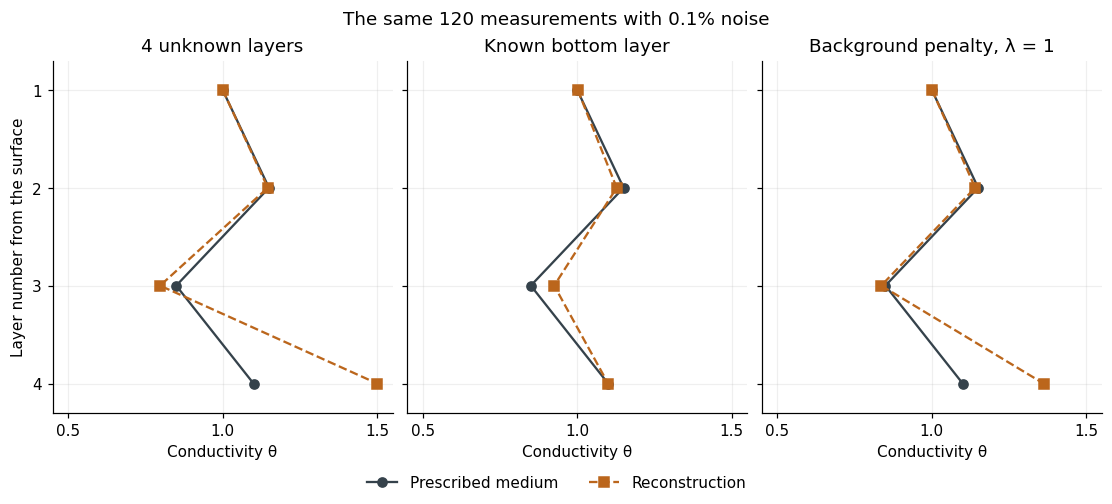

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4.5), sharex=True, sharey=True, layout="constrained")
for ax, key in zip(axes, ("noisy", "known", "prior")):
    ax.plot(truth, range(1, 5), "o-", color="#35424B", label=TEXT["truth"])
    ax.plot(fits[key][0], range(1, 5), "s--", color="#BB661C", label=TEXT["estimate"])
    ax.set(title=TEXT[key], xlabel=TEXT["conductivity"], xlim=(0.45, 1.55),
           ylim=(4.3, 0.7), xticks=[0.5, 1.0, 1.5], yticks=range(1, 5))
    ax.grid(alpha=0.2)
axes[0].set_ylabel(TEXT["layer"])
handles, labels_legend = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_legend, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle(TEXT["layers_title"])
fig.savefig("electrometry-layers.svg", bbox_inches="tight")
plt.show()

## Checks and open questions

The notebook checks the four-resistance identity, the measurement rank on four electrodes, ideal planar geometry, real-grid alignment, resistance preservation under reduction, two variation formulas, and inversion of the effective network's pair matrices. The layered-model Jacobian is checked independently of fitting, and the fitted models are recomputed through the package.

These examples do not establish the number of informative modes in real data or a minimal field measurement set. Such conclusions require an error model, an admissible class of media, and a criterion for retaining information. Changing the data or model also requires reconsidering the reference numbers.

A further experiment is to vary the noise level or the measured pair set and compare residuals, parameter errors, and Jacobian singular values together. A spectrum or a residual alone cannot assess reconstruction quality.